# What makes molecular replacement succeed? Explaining the models honestly

**Group project · structural biology, part 1 · my implementation**, Seid Adem

> **Why this matters, in plain language.** To see a protein's 3-D structure by X-ray crystallography, scientists
> shine X-rays through a protein crystal and record the diffraction pattern. Turning that pattern into a structure
> needs information that the experiment loses (the "phases"). **Molecular replacement (MR)** recovers it by
> borrowing a known, similar structure (a **search model**). Sometimes it works, sometimes not, and a failed attempt
> costs computer time and a scientist's day. The course tutorial predicts **MR success** from numbers describing the
> diffraction data. ([Lesson 1](../LESSONS.md))

In [module 03.2](../../../03_foundations_of_machine_learning/02_hyperparameters_and_performance/implementation/) I audited this dataset and found that a fair evaluation must **keep all rows
of a crystal together** (random splits inflate AUC from 0.74 to 0.93), and that the **sequence identity** between
the protein and its search model, known before MR but unused by the course, lifts AUC to about 0.87.

This notebook asks the next question: **why** do the models predict what they predict, and do those reasons make
sense to a crystallographer? I use **SHAP**, with three safeguards that are often skipped:

1. explanations are computed only for **crystals the model never saw** (out-of-fold);
2. their **stability** across 25 different training sets is checked;
3. **correlated features** (several near-identical quality statistics) are grouped, so credit split between twins
   isn't misread as "unimportant".

> **In plain language: SHAP.** For one prediction, SHAP divides "how far this prediction is from the average
> prediction" among the input features, so that the parts add up exactly. A feature with a large positive SHAP value
> pushed this crystal's predicted success up. Averaging the size of these parts over many crystals ranks features by
> how much the model relies on them. It explains **the model**, not the physics: a model can rely on a feature for
> the wrong reason.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from dsls.mr import COURSE_FEATURES, GROUP, LABEL, load_mr_data

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path(
    "../../../03_foundations_of_machine_learning/02_hyperparameters_and_performance/course_materials/DataScience_EBI/tutorials/data.csv"
)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
SEED = 0

df = load_mr_data(DATA)
# One attempt lists a search-model resolution of 73 Å (all others: 1.0–3.7 Å). It is impossible, so treat it as
# missing (imputed inside the pipeline). Left in, it gives logistic regression a −32 log-odds push for that row.
print("model_res above 10 Å:", df.loc[df["model_res"] > 10, "model_res"].tolist(), "→ set to missing")
df.loc[df["model_res"] > 10, "model_res"] = np.nan
FEATURES = COURSE_FEATURES + ["seq_ident"]
X, y, groups = df[FEATURES], df[LABEL].to_numpy(), df[GROUP].to_numpy()
print(
    f"{len(df)} MR attempts from {df[GROUP].nunique()} crystals; success rate {y.mean():.0%}; {len(FEATURES)} features known before MR"
)
print(f"shap {shap.__version__}")

# Feature families: statistics that measure the same thing are grouped so their credit can be added up
FAMILIES = {
    "search model": ["seq_ident", "eLLG", "model_res"],
    "resolution": ["mr_reso", "highreslimit", "lowreslimit"],
    "data quality": ["IoverSigma", "cchalf", "completeness", "RmergeI", "RmeasI", "RpimI", "multiplicity",
                     "totalobservations", "totalunique", "wilsonbfactor"],
    "anomalous signal": ["anomalousCC", "anomalousslope", "anomalousmulti", "anomalouscompl", "diffI", "diffF",
                         "RmergediffI", "RmeasdiffI", "RpimdiffI"],
    "crystal & experiment": ["wavelength", "mr_sg_no", "tncs"],
}  # fmt: skip
family_of = {f: fam for fam, feats in FAMILIES.items() for f in feats}
assert sorted(family_of) == sorted(FEATURES), set(FEATURES) ^ set(family_of)

model_res above 10 Å: [73.0] → set to missing
663 MR attempts from 359 crystals; success rate 44%; 28 features known before MR
shap 0.54.1


## 1 · Two models, explained on unseen crystals

* **Logistic regression** (impute → standardise → linear model): each feature has one weight, so its SHAP value is
  simply weight × (standardised value), in log-odds.
* **Random forest**, kept shallow (depth 4, as nested tuning chose in 03.2): it can capture thresholds and
  interactions. SHAP values come from the exact tree algorithm, in units of predicted probability.

5-fold cross-validation **grouped by crystal**, repeated 5 times with different splits: 25 training sets, and every
attempt explained 5 times by models that never saw its crystal.

In [2]:
def make_lr():
    return make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)
    )


def make_rf():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED, n_jobs=-1))  # fmt: skip


REPEATS = 5
records = {"logistic regression": [], "random forest": []}
oof = {name: np.zeros((REPEATS, len(y))) for name in records}
for r in range(REPEATS):
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
    for k, (train, test) in enumerate(folds.split(X, y, groups)):
        lr = make_lr().fit(X.iloc[train], y[train])
        Z = lr[:-1].transform(X.iloc[test])  # imputed + standardised with training statistics
        phi_lr = Z * lr[-1].coef_[0]
        rf = make_rf().fit(X.iloc[train], y[train])
        Xi = rf[0].transform(X.iloc[test])
        phi_rf = shap.TreeExplainer(rf[-1]).shap_values(Xi)[:, :, 1]
        for name, model, phi in (("logistic regression", lr, phi_lr), ("random forest", rf, phi_rf)):
            oof[name][r, test] = model.predict_proba(X.iloc[test])[:, 1]
            records[name].append(pd.DataFrame(phi, columns=FEATURES, index=test).assign(repeat=r, fold=k))

for name in records:
    aucs = [roc_auc_score(y, oof[name][r]) for r in range(REPEATS)]
    print(f"{name:20s} grouped AUC {np.mean(aucs):.3f} (repeats {min(aucs):.3f}–{max(aucs):.3f})")
shap_values = {name: pd.concat(parts) for name, parts in records.items()}

logistic regression  grouped AUC 0.857 (repeats 0.850–0.867)
random forest        grouped AUC 0.879 (repeats 0.876–0.881)


**Both models predict well on unseen crystals:** AUC 0.857 for logistic regression and 0.879 for the random forest,
in line with 03.2 (0.86–0.88 with sequence identity). The forest is very stable across repeats (0.876–0.881). One
data fix first: a search-model resolution of 73 Å (all others are 1.0–3.7 Å) is treated as missing, because a
linear model extrapolates from such a value and gave that one attempt a −32 log-odds push.

## 2 · Which features does each model rely on?

,logistic regression,random forest,family
seq_ident,28.2%,40.1%,search model
eLLG,5.5%,17.0%,search model
diffF,1.2%,6.3%,anomalous signal
totalobservations,3.1%,4.3%,data quality
anomalousCC,8.4%,3.7%,anomalous signal
diffI,2.3%,3.7%,anomalous signal
totalunique,4.8%,2.9%,data quality
anomalousmulti,1.2%,2.4%,anomalous signal
wilsonbfactor,3.1%,2.2%,data quality
multiplicity,0.7%,1.9%,data quality


rank agreement between the two models over all 28 features: Spearman 0.27


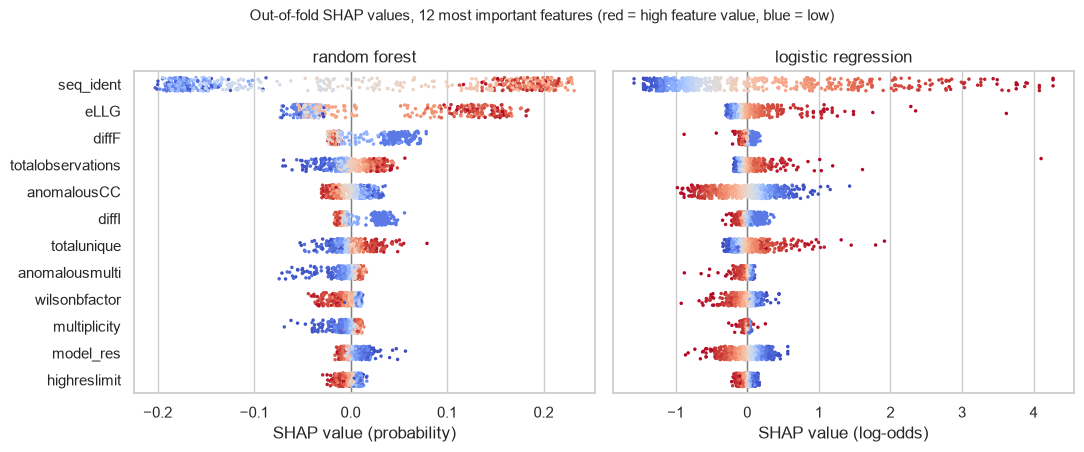

In [3]:
importance = pd.DataFrame({name: s[FEATURES].abs().mean() for name, s in shap_values.items()})
importance = importance / importance.sum()  # share of the total, so the two models are comparable
importance["family"] = importance.index.map(family_of)
top = importance.sort_values("random forest", ascending=False)
display(top.head(10).style.format({"logistic regression": "{:.1%}", "random forest": "{:.1%}"}))
rho = spearmanr(importance["logistic regression"], importance["random forest"]).statistic
print(f"rank agreement between the two models over all {len(FEATURES)} features: Spearman {rho:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
order = top.index[:12]
for ax, name in zip(axes, ("random forest", "logistic regression"), strict=True):
    s = shap_values[name].groupby(level=0)[FEATURES].mean()  # average the 5 explanations of each attempt
    long = s[order].melt(var_name="feature", value_name="SHAP")
    long["value (rank within feature)"] = X[order].rank(pct=True).melt()["value"].to_numpy()
    sns.stripplot(data=long, x="SHAP", y="feature", hue="value (rank within feature)", palette="coolwarm", size=2.5,
                  jitter=0.25, legend=False, ax=ax)  # fmt: skip
    ax.axvline(0, color="grey", lw=1)
    ax.set(
        title=name,
        xlabel="SHAP value (" + ("probability" if name == "random forest" else "log-odds") + ")",
        ylabel="",
    )
    lo, hi = long["SHAP"].quantile([0.001, 0.999])
    if name == "logistic regression" and long["SHAP"].min() < lo - 5:
        outlier = long.loc[long["SHAP"].idxmin()]
        ax.set_xlim(lo - 0.5, hi + 0.5)
        ax.text(
            0.02,
            0.02,
            f"1 point off-axis: {outlier['feature']} = {outlier['SHAP']:.0f}",
            transform=ax.transAxes,
            fontsize=8,
        )
fig.suptitle(
    "Out-of-fold SHAP values, 12 most important features (red = high feature value, blue = low)", fontsize=11
)
fig.tight_layout()
fig.savefig(FIGURES / "01_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

**Both models put sequence identity first** (28 % of the logistic model's total |SHAP|, 40 % of the forest's), and
the forest adds **eLLG** (17 %), the expected strength of the MR signal, which is itself computed from the search
model. Beyond those two, the models disagree: rank agreement across all 28 features is only Spearman 0.27. The forest
next uses the **anomalous differences** (diffF, diffI) and **dataset size** (total observations); the logistic model
uses **anomalousCC** (8 %).

> **How to read the strip plot.** Each dot is one attempt; red means a high value of that feature, blue a low one.
> For sequence identity, red dots sit on the right (high identity pushes towards success). For diffF, *blue* dots sit
> on the right: **a weak anomalous signal pushes towards success**, which is surprising, since MR doesn't use the
> anomalous signal. Section 4 looks into it.

## 3 · Are the explanations stable?

If an importance ranking changes a lot when the training crystals change, it describes the sample, not the problem.
For each of the 25 training sets, rank the features by mean |SHAP| on that fold's unseen crystals:

In [4]:
rows = []
for name, s in shap_values.items():
    for _, part in s.groupby(["repeat", "fold"]):
        ranks = part[FEATURES].abs().mean().rank(ascending=False)
        rows += [{"model": name, "feature": f, "rank": ranks[f]} for f in FEATURES]
ranks = pd.DataFrame(rows)
summary = ranks.groupby(["model", "feature"])["rank"].agg(["median", "min", "max"]).unstack(0)
rf_order = summary[("median", "random forest")].sort_values().index
display(summary.loc[rf_order[:10]].astype(int))
for name in shap_values:
    first = ranks[(ranks["model"] == name)].query("rank == 1")["feature"].value_counts()
    print(f"{name}: ranked first in 25 folds → " + ", ".join(f"{f} ({n})" for f, n in first.items()))

median                               min  \
model             logistic regression random forest logistic regression   
feature                                                                   
seq_ident                           1             1                   1   
eLLG                                4             2                   2   
diffF                              23             3                   8   
totalobservations                  12             4                   3   
diffI                              16             5                   4   
anomalousCC                         2             5                   2   
totalunique                         5             7                   2   
anomalousmulti                     22             9                  10   
wilsonbfactor                      10             9                   3   
multiplicity                       25            11                  15   

                                                max                
model             random forest logistic regression random forest  
feature                                                            
seq_ident                     1                   1             1  
eLLG                          2                  17             2  
diffF                         3                  28             5  
totalobservations             3                  24            11  
diffI                         4                  28             9  
anomalousCC                   3                   6            10  
totalunique                   4                  23            12  
anomalousmulti                4                  28            13  
wilsonbfactor                 6                  25            20  
multiplicity                  5                  28            18

logistic regression: ranked first in 25 folds → seq_ident (25)
random forest: ranked first in 25 folds → seq_ident (25)


**The top of the ranking is solid; the rest is not.** Sequence identity ranks first in **all 25 folds** for both
models, and eLLG is second in every fold for the forest. Lower down, ranks wander: for the logistic model diffF
ranges from 8th to 28th, total observations from 3rd to 24th. Only the top one or two features should be read as
reliable findings.

## 4 · Correlated features share credit: look at families

Rmerge, Rmeas and Rpim are three versions of the same agreement statistic (|r| > 0.98 between some of them). A
model can use any one of them, so SHAP may split the credit or give it all to one, and the split can change from
fold to fold. Adding |SHAP| within each **family** of related features gives a more robust picture:

In [5]:
fam = pd.DataFrame(
    {name: s[FEATURES].abs().T.groupby(family_of).sum().T.mean() for name, s in shap_values.items()}
)
fam = (fam / fam.sum()).sort_values("random forest", ascending=False)
display(fam.style.format("{:.0%}"))

within = importance.groupby("family")["random forest"].agg(lambda v: v.max() / v.sum())
print("random forest: share of each family's credit taken by its single top feature →",
      ", ".join(f"{k} {v:.0%}" for k, v in within.items()))  # fmt: skip

,logistic regression,random forest
search model,38%,59%
anomalous signal,25%,19%
data quality,29%,16%
resolution,4%,5%
crystal & experiment,3%,2%


random forest: share of each family's credit taken by its single top feature → anomalous signal 33%, crystal & experiment 56%, data quality 28%, resolution 36%, search model 68%


**Summed by family, the picture is clearer:** the **search model** family (sequence identity, eLLG, model
resolution) carries **59 %** of the forest's reliance and 38 % of the logistic model's. The anomalous-signal family
comes next (19–25 %), then data quality (16–29 %). **Resolution and crystal/experiment features barely matter
(2–5 %).**

Within the families, a single feature takes only 28–36 % of the credit for data quality, resolution and anomalous
signal: the credit is spread over twins, which is why their individual ranks were unstable.

### Why would the anomalous signal matter for MR?

Molecular replacement doesn't use the anomalous signal at all: it is the small difference between "Friedel pairs"
that *experimental* phasing methods (SAD/MAD) exploit. Yet both models lean on it. A likely explanation is **study
design**: crystallographers collect data for anomalous phasing when they *don't* expect a good search model. If so,
the anomalous signal is a **proxy** for "no close homologue was known", not a cause of MR failure.

Two checks: (1) does the link survive *within* bands of sequence identity? (2) how much AUC is lost if the whole
anomalous family is removed?

In [6]:
outcome = pd.Series(y, index=X.index)
anom = pd.qcut(X["diffF"], 4, labels=["lowest", "2nd", "3rd", "highest"])
ident = pd.cut(X["seq_ident"], [0, 30, 50, 100], labels=["≤ 30 %", "30–50 %", "> 50 %"])
print("median sequence identity by quarter of anomalous signal (diffF):",
      X["seq_ident"].groupby(anom, observed=True).median().round(0).to_dict())  # fmt: skip
print("\nMR success rate by sequence identity (rows) and anomalous signal (columns); attempts in brackets")
rate = outcome.groupby([ident, anom], observed=True).mean().unstack()
count = outcome.groupby([ident, anom], observed=True).size().unstack()
display(rate.round(2).astype(str) + " (" + count.astype(str) + ")")


def grouped_auc(make_model, columns):
    aucs = []
    for r in range(REPEATS):
        pred = np.zeros(len(y))
        for train, test in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r).split(X, y, groups):
            pred[test] = (
                make_model().fit(X.iloc[train][columns], y[train]).predict_proba(X.iloc[test][columns])[:, 1]
            )
        aucs.append(roc_auc_score(y, pred))
    return np.mean(aucs)


no_anom = [f for f in FEATURES if family_of[f] != "anomalous signal"]
for name, maker in (("logistic regression", make_lr), ("random forest", make_rf)):
    print(f"{name:20s} grouped AUC: all features {grouped_auc(maker, FEATURES):.3f} → without the anomalous family "
          f"{grouped_auc(maker, no_anom):.3f} → search model only {grouped_auc(maker, FAMILIES['search model']):.3f}")  # fmt: skip

median sequence identity by quarter of anomalous signal (diffF): {'lowest': 54.0, '2nd': 29.0, '3rd': 30.0, 'highest': 28.0}

MR success rate by sequence identity (rows) and anomalous signal (columns); attempts in brackets


diffF,lowest,2nd,3rd,highest
seq_ident,,,,
≤ 30 %,0.23 (35),0.07 (87),0.05 (82),0.11 (92)
30–50 %,0.6 (43),0.62 (50),0.58 (55),0.53 (30)
> 50 %,0.9 (88),0.72 (32),0.83 (30),0.87 (39)


logistic regression  grouped AUC: all features 0.857 → without the anomalous family 0.856 → search model only 0.874


random forest        grouped AUC: all features 0.879 → without the anomalous family 0.875 → search model only 0.885


**The anomalous signal is a proxy, not a cause.** Attempts with the weakest anomalous signal have a median sequence
identity of **54 %**, against 28–30 % for the rest: the datasets without anomalous signal were mostly collected when
a close homologue was already known. *Within* a band of sequence identity, the link largely disappears (for example
0.53–0.62 success at 30–50 % identity, whatever the anomalous signal). The one exception is the weakest-signal group
at ≤ 30 % identity (0.23 vs 0.05–0.11), and it contains only 35 attempts.

**And the models don't need it:** removing all nine anomalous features changes AUC by at most 0.004. Even more
striking, the **three search-model features alone** do as well as all 28 (logistic 0.874, forest 0.885).

> **In plain language.** A model can lean on a feature that merely *travels with* the real cause. Here, "the
> experimenter collected anomalous data" travels with "there was no good search model". SHAP faithfully reports that
> the model uses it; only domain knowledge and a stratified check reveal why.

## 5 · Do the relationships make physical sense?

A **dependence plot** shows a feature's SHAP value against the feature itself: the shape of what the model learned.

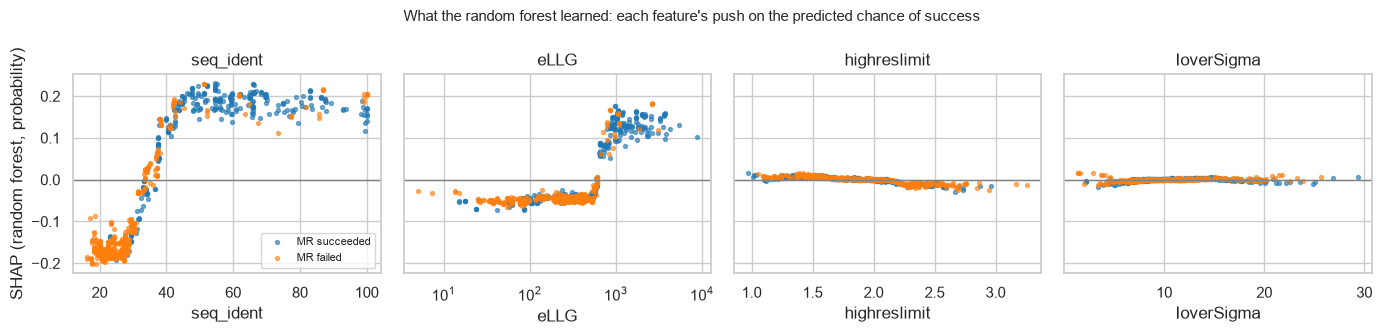

seq_ident: the average SHAP turns positive in the bin (33.33, 36.81]
eLLG: the average SHAP turns positive in the bin (653.35, 849.1]

           attempts  MR success rate  mean SHAP
seq_ident                                      
(0, 30]         296             0.09     -0.164
(30, 50]        178             0.59      0.074
(50, 100]       189             0.85      0.186


In [7]:
s_rf = shap_values["random forest"].groupby(level=0)[FEATURES].mean()
show = ["seq_ident", "eLLG", "highreslimit", "IoverSigma"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, f in zip(axes, show, strict=True):
    for outcome_value, colour, label in ((1, "tab:blue", "MR succeeded"), (0, "tab:orange", "MR failed")):
        m = y == outcome_value
        ax.scatter(X.loc[m, f], s_rf.loc[m, f], color=colour, s=8, alpha=0.6, label=label)
    ax.axhline(0, color="grey", lw=1)
    ax.set(xlabel=f, title=f)
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("SHAP (random forest, probability)")
if X["eLLG"].max() / max(X["eLLG"].min(), 1e-9) > 100:
    axes[1].set_xscale("log")
fig.suptitle(
    "What the random forest learned: each feature's push on the predicted chance of success", fontsize=11
)
fig.tight_layout()
fig.savefig(FIGURES / "02_shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

for f in ("seq_ident", "eLLG"):
    crossing = s_rf[f].groupby(pd.qcut(X[f], 20, duplicates="drop"), observed=True).mean()
    first_up = crossing[crossing > 0].index[0]
    print(f"{f}: the average SHAP turns positive in the bin {first_up}")
print()
for f, lo, hi in (("seq_ident", 30, 50),):
    bins = pd.cut(X[f], [0, lo, hi, 100])
    outcome = pd.Series(y, index=X.index)
    print(pd.DataFrame({"attempts": outcome.groupby(bins, observed=True).size(),
                        "MR success rate": outcome.groupby(bins, observed=True).mean().round(2),
                        "mean SHAP": s_rf[f].groupby(bins, observed=True).mean().round(3)}))  # fmt: skip

**The shapes match crystallographic experience.** For **sequence identity**, the forest's push turns positive between
33 % and 37 % identity and levels off above about 42 %; below 30 %, success is rare (9 % of 296 attempts) and the
push is strongly negative. That is the familiar "MR gets hard below about 30 % identity" rule, found from the data.
**eLLG** behaves like a threshold too, turning positive between about 650 and 850. A random forest can only build
step functions, so the sharpness is partly the model's; the existence of a threshold is the finding. **Resolution
and I/σ** hardly move the prediction (within ±0.02).

## 6 · Error analysis: which attempts does the model get wrong, and why?

Average the 5 out-of-fold predictions of each attempt (random forest) and look at the most confident mistakes.

In [8]:
p = oof["random forest"].mean(axis=0)
errors = pd.DataFrame({"crystal": groups, "MR success": y, "predicted P(success)": p.round(2),
                       "seq_ident": X["seq_ident"], "eLLG": X["eLLG"].round(0), "highreslimit": X["highreslimit"]})  # fmt: skip
# one row per crystal (several attempts of the same crystal look almost identical)
fn = (
    errors[(errors["MR success"] == 1)].sort_values("predicted P(success)").drop_duplicates("crystal").head(6)
)
fp = (
    errors[(errors["MR success"] == 0)]
    .sort_values("predicted P(success)", ascending=False)
    .drop_duplicates("crystal")
    .head(6)
)
print(f"at a 0.5 threshold: {((p < 0.5) & (y == 1)).sum()} successes predicted to fail, "
      f"{((p >= 0.5) & (y == 0)).sum()} failures predicted to succeed (of {y.sum()} / {(1 - y).sum()})")  # fmt: skip
print("\nmost confident misses (succeeded, predicted to fail):")
display(fn)
print("most confident false alarms (failed, predicted to succeed):")
display(fp)
print("median of all attempts:", errors[["seq_ident", "eLLG", "highreslimit"]].median().round(2).to_dict())

missed = errors.index[(p < 0.5) & (y == 1)]
top_reason = s_rf.loc[missed].apply(lambda row: row.idxmin(), axis=1)
print(f"\nfor all {len(missed)} missed successes, the feature that pushed hardest towards 'fail':")
print(top_reason.value_counts().head(5).to_string())
print(
    f"missed successes with sequence identity ≤ 30 %: {(X.loc[missed, 'seq_ident'] <= 30).mean():.0%} "
    f"(all successes: {(X.loc[y == 1, 'seq_ident'] <= 30).mean():.0%})"
)

at a 0.5 threshold: 60 successes predicted to fail, 46 failures predicted to succeed (of 294 / 369)

most confident misses (succeeded, predicted to fail):


,crystal,MR success,predicted P(success),seq_ident,eLLG,highreslimit
48,1095,1,0.14,23.39,96.0,1.99
54,1113,1,0.14,26.42,309.0,1.94
618,916,1,0.15,29.38,192.0,2.18
502,669,1,0.17,24.85,131.0,2.08
285,300,1,0.17,29.27,193.0,2.46
341,401,1,0.18,22.97,37.0,1.45


most confident false alarms (failed, predicted to succeed):


,crystal,MR success,predicted P(success),seq_ident,eLLG,highreslimit
147,1293,0,0.89,45.30,713.0,1.57
359,423,0,0.88,64.79,1853.0,1.94
80,1180,0,0.86,42.61,977.0,1.23
118,1247,0,0.85,42.61,966.0,1.16
557,791,0,0.84,81.73,3118.0,1.76
99,1216,0,0.83,61.85,1072.0,2.02


median of all attempts: {'seq_ident': 33.33, 'eLLG': 353.0, 'highreslimit': 1.84}

for all 60 missed successes, the feature that pushed hardest towards 'fail':
seq_ident            35
eLLG                 19
anomalousmulti        4
totalobservations     2
missed successes with sequence identity ≤ 30 %: 45% (all successes: 10%)


**The mistakes are the hard cases of crystallography, not modelling bugs:**

* **Missed successes** are mostly attempts with **low sequence identity that worked anyway** (all six shown are at
  23–29 %). 45 % of all 60 missed successes are at ≤ 30 % identity, against 10 % of successes overall, and for 35 of
  the 60 sequence identity was the feature that pushed hardest towards "fail".
* **False alarms** are attempts with a **good search model that still failed** (42–82 % identity, eLLG 713–3,118).
  Nothing in these 28 numbers explains them. Likely causes lie in things the data don't record (for example
  conformational differences, twinning or several copies in the asymmetric unit), but that is a hypothesis.

> **What would help next:** features describing *how* the search model differs from the target (coverage,
> predicted structural similarity) rather than more data-quality statistics.

## Conclusions

1. **MR success is mostly decided by the search model.** Sequence identity ranks first in all 25 folds for both
   models, and the three search-model features alone reach AUC 0.87–0.89, as good as all 28.
2. **The data-quality statistics the tutorial focuses on add almost nothing** once the search model is known;
   resolution and I/σ barely move predictions.
3. **The anomalous signal is a proxy for study design**, not physics: anomalous data were collected when no close
   homologue existed. Removing it costs ≤ 0.004 AUC.
4. **Interpret explanations with care:** two equally accurate models agreed only on the top two features (rank
   agreement 0.27 overall); correlated twins split credit, so families are more robust than single features.
5. **One impossible value (73 Å) distorted the linear model's explanations**, a reminder that interpretation is
   only as good as the data audit.

**Limitations.** 663 attempts from 359 crystals from two structural-genomics centres; SHAP explains these models, not
causal effects; the proxy interpretation rests on a stratified table with small cells.

*Data: the course's MR dataset (`DataScience_EBI` tutorial, MIT licence), cleaned with
[`dsls.mr`](../../../src/dsls/mr.py). Runtime: about 1 minute.*